In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, HuberRegressor
from sklearn.datasets import fetch_california_housing, make_classification
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')


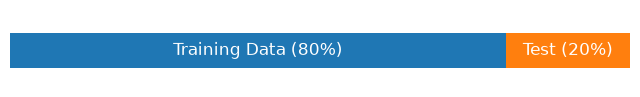

In [2]:
fig, ax = plt.subplots(figsize=(8, 1))
_temp = ax.broken_barh([(0, 80)], (10, 9), facecolors='tab:blue')
_temp = ax.broken_barh([(80, 20)], (10, 9), facecolors='tab:orange')
_temp = ax.text(40, 14.5, 'Training Data (80%)', color='white', fontsize=12, ha='center', va='center')
_temp = ax.text(90, 14.5, 'Test (20%)', color='white', fontsize=12, ha='center', va='center')
_temp = ax.set_xlim(0, 100)
_temp = ax.set_ylim(5, 25)
_temp = ax.axis('off')
plt.show()


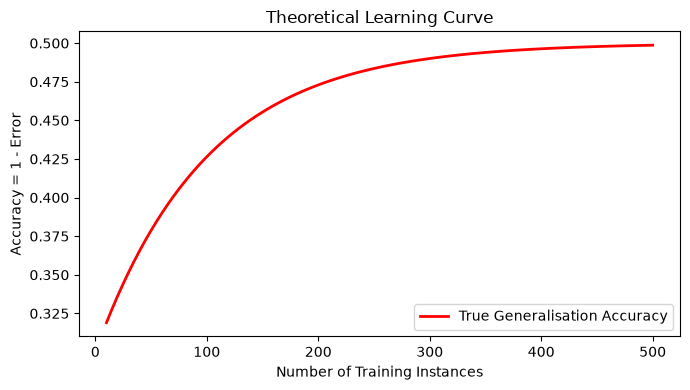

In [3]:
train_sizes = np.linspace(10, 500, 100)
test_err = 0.5 - 0.2 * np.exp(-train_sizes / 100)

_temp = plt.figure(figsize=(7, 4))
_temp = plt.plot(train_sizes, test_err, 'r-', lw=2, label='True Generalisation Accuracy')
_temp = plt.xlabel('Number of Training Instances')
_temp = plt.ylabel('Accuracy = 1 - Error')
_temp = plt.title('Theoretical Learning Curve')
_temp = plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


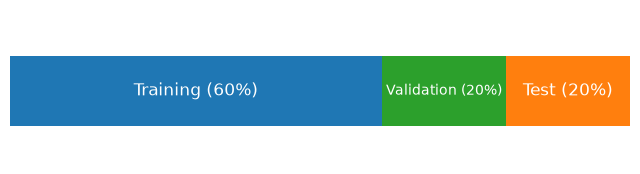

In [4]:
fig, ax = plt.subplots(figsize=(8, 2))
_temp = ax.broken_barh([(0, 60)], (10, 9), facecolors='tab:blue')
_temp = ax.broken_barh([(60, 20)], (10, 9), facecolors='tab:green')
_temp = ax.broken_barh([(80, 20)], (10, 9), facecolors='tab:orange')
_temp = ax.text(30, 14.5, 'Training (60%)', color='white', fontsize=12, ha='center', va='center')
_temp = ax.text(70, 14.5, 'Validation (20%)', color='white', fontsize=10, ha='center', va='center')
_temp = ax.text(90, 14.5, 'Test (20%)', color='white', fontsize=12, ha='center', va='center')
_temp = ax.set_xlim(0, 100)
_temp = ax.set_ylim(5, 25)
_temp = ax.axis('off')
plt.show()


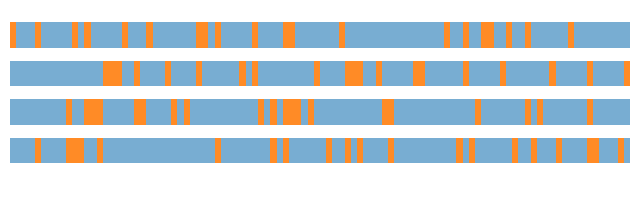

In [5]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 2.5))
np.random.seed(42) # Keeps the random layout stable across slide renders

for i in range(4):
    # Create 100 total units, randomly pick 20 for validation (orange)
    indices = np.arange(100)
    val_indices = np.random.choice(indices, size=20, replace=False)
    
    # Map the indices to (start_pos, width) tuples required by broken_barh
    blue_ranges = [(x, 1) for x in indices if x not in val_indices]
    orange_ranges = [(x, 1) for x in val_indices]
    
    _temp = ax.broken_barh(blue_ranges, (10 - i*3, 2), facecolors='tab:blue', alpha=0.6)
    _temp = ax.broken_barh(orange_ranges, (10 - i*3, 2), facecolors='tab:orange', alpha=0.9)

_temp = ax.set_xlim(0, 100)
_temp = ax.set_ylim(-2, 13)
_temp = ax.axis('off')
plt.show()


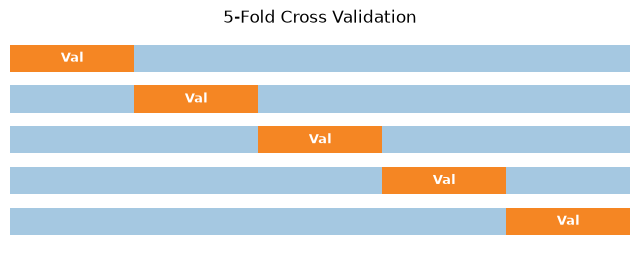

In [6]:
fig, ax = plt.subplots(figsize=(8, 3))
for i in range(5):
    _temp = ax.broken_barh([(0, 100)], (12 - i*3, 2), facecolors='tab:blue', alpha=0.4)
    _temp = ax.broken_barh([(i*20, 20)], (12 - i*3, 2), facecolors='tab:orange', alpha=0.9)
    _temp = ax.text(i*20 + 10, 12 - i*3 + 1, 'Val', color='white', ha='center', va='center', fontsize=9, fontweight='bold')
_temp = ax.set_xlim(0, 100)
_temp = ax.set_ylim(-2, 15)
_temp = ax.axis('off')
plt.title("5-Fold Cross Validation")
plt.show()


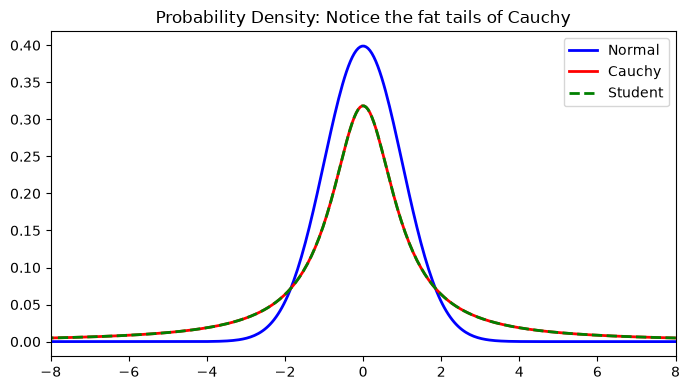

In [7]:
x = np.linspace(-10, 10, 400)
_temp = plt.figure(figsize=(7, 4))
_temp = plt.plot(x, stats.norm.pdf(x), 'b-', lw=2, label='Normal')
_temp = plt.plot(x, stats.cauchy.pdf(x), 'r-', lw=2, label='Cauchy')
_temp = plt.plot(x, stats.t.pdf(x, df=1), 'g--', lw=2, label='Student')
_temp = plt.xlim(-8, 8)
_temp = plt.title("Probability Density: Notice the fat tails of Cauchy")
_temp = plt.legend()
plt.tight_layout()
plt.show()


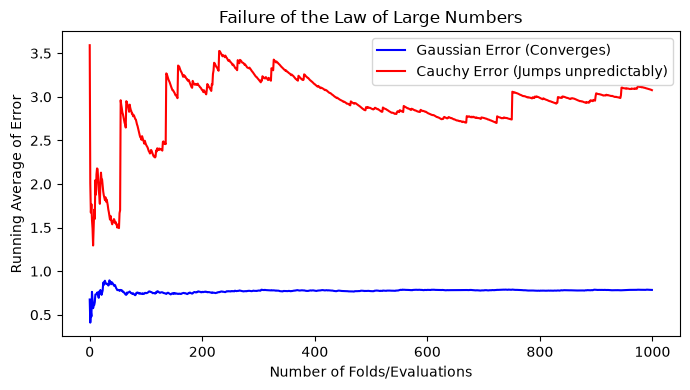

In [20]:
np.random.seed(42)
cauchy_data = np.abs(np.random.standard_cauchy(1000))
norm_data = np.abs(np.random.standard_normal(1000))

run_mean_cauchy = np.cumsum(cauchy_data) / np.arange(1, 1001)
run_mean_norm = np.cumsum(norm_data) / np.arange(1, 1001)

_temp = plt.figure(figsize=(7, 4))
_temp = plt.plot(run_mean_norm, 'b-', label='Gaussian Error (Converges)')
_temp = plt.plot(run_mean_cauchy, 'r-', label='Cauchy Error (Jumps unpredictably)')
_temp = plt.xlabel('Number of Folds/Evaluations')
_temp = plt.ylabel('Running Average of Error')
_temp = plt.title('Failure of the Law of Large Numbers')
_temp = plt.legend()
plt.tight_layout()
plt.show()


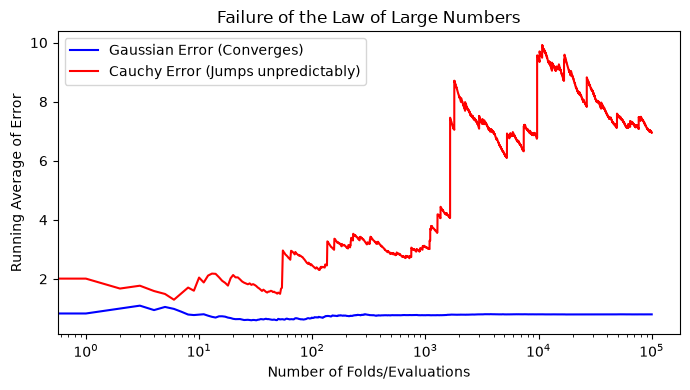

In [27]:
np.random.seed(42)

max_value = 10**5

cauchy_data = np.abs(np.random.standard_cauchy(max_value))
norm_data = np.abs(np.random.standard_normal(max_value))

run_mean_cauchy = np.cumsum(cauchy_data) / np.arange(1, max_value + 1)
run_mean_norm = np.cumsum(norm_data) / np.arange(1, max_value + 1)

_temp = plt.figure(figsize=(7, 4))
_temp = plt.plot(run_mean_norm, 'b-', label='Gaussian Error (Converges)')
_temp = plt.plot(run_mean_cauchy, 'r-', label='Cauchy Error (Jumps unpredictably)')
_temp = plt.xlabel('Number of Folds/Evaluations')
_temp = plt.ylabel('Running Average of Error')
_temp = plt.title('Failure of the Law of Large Numbers')
_temp = plt.xscale('log')
_temp = plt.legend()
plt.tight_layout()
plt.show()


In [11]:
cal_X, cal_y = fetch_california_housing(return_X_y=True)
cal_X_sample, cal_y_sample = cal_X[:1000], cal_y[:1000] # Subsample for speed
scaler = StandardScaler()
X_sc = scaler.fit_transform(cal_X_sample)

grid = {'alpha': [0.1, 1.0, 10.0]}
gs = GridSearchCV(Ridge(), grid, cv=3)
_temp = gs.fit(X_sc, cal_y_sample)

df_gs = pd.DataFrame(gs.cv_results_)[['param_alpha', 'mean_test_score', 'rank_test_score']]
df_gs.columns = ['Ridge Alpha', 'Mean CV R²', 'Rank']
print(df_gs.to_markdown(index=False))


|   Ridge Alpha |   Mean CV R² |   Rank |
|--------------:|-------------:|-------:|
|           0.1 |     0.302376 |      3 |
|           1   |     0.302545 |      2 |
|          10   |     0.304284 |      1 |


In [12]:
param_dist = {
    'alpha': stats.loguniform(1e-2, 1e1),
    'l1_ratio': stats.uniform(0, 1)
}
rs = RandomizedSearchCV(ElasticNet(), param_dist, n_iter=3, cv=3, random_state=42)
_temp = rs.fit(X_sc, cal_y_sample)

df_rs = pd.DataFrame(rs.cv_results_)[['param_alpha', 'param_l1_ratio', 'mean_test_score']]
df_rs['param_alpha'] = df_rs['param_alpha'].apply(lambda x: f"{x:.4f}")
df_rs['param_l1_ratio'] = df_rs['param_l1_ratio'].apply(lambda x: f"{x:.4f}")
df_rs.columns = ['EN Alpha', 'L1 Ratio', 'Mean CV R²']
print(df_rs.to_markdown(index=False))


|   EN Alpha |   L1 Ratio |   Mean CV R² |
|-----------:|-----------:|-------------:|
|     0.1329 |     0.9507 |     0.481622 |
|     1.5703 |     0.5987 |    -0.202194 |
|     0.0294 |     0.156  |     0.333661 |


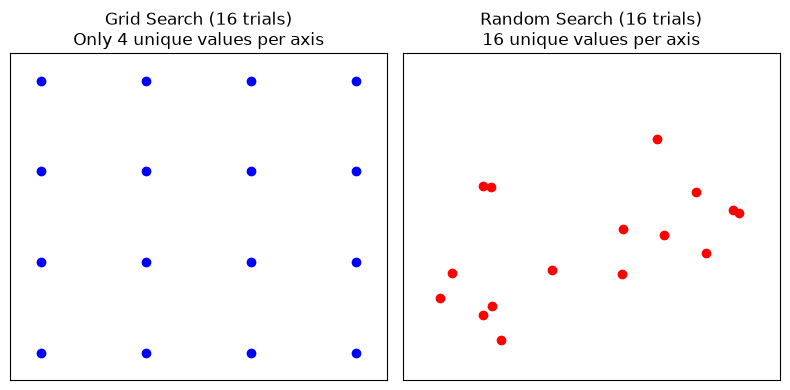

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Grid
xg = np.linspace(0, 1, 4)
yg = np.linspace(0, 1, 4)
Xg, Yg = np.meshgrid(xg, yg)
_temp = axes[0].scatter(Xg, Yg, color='blue')
_temp = axes[0].set_title('Grid Search (16 trials)\nOnly 4 unique values per axis')

# Random
np.random.seed(42)
xr = np.random.uniform(0, 1, 16)
yr = np.random.uniform(0, 1, 16)
_temp = axes[1].scatter(xr, yr, color='red')
_temp = axes[1].set_title('Random Search (16 trials)\n16 unique values per axis')

for ax in axes:
    _temp = ax.set_xticks([])
    _temp = ax.set_yticks([])
    _temp = ax.set_xlim(-0.1, 1.1)
    _temp = ax.set_ylim(-0.1, 1.1)

plt.tight_layout()
plt.show()


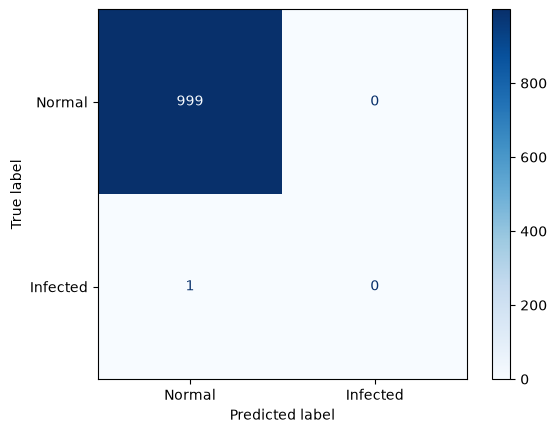

In [14]:
y_true = np.array([0]*999 + [1]*1)
y_pred = np.array([0]*1000) # Always predict majority

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Infected'])
_temp = disp.plot(cmap='Blues', values_format='d')
plt.show()



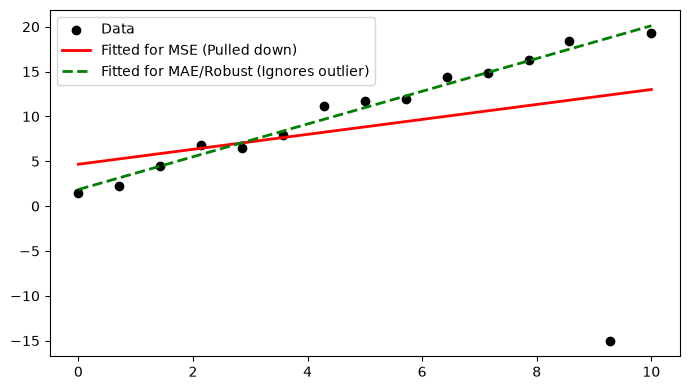

In [15]:


np.random.seed(42)
x = np.linspace(0, 10, 15)
y = 2 * x + 1 + np.random.normal(0, 1, 15)
y[13] = -15 # Extreme outlier

lr = LinearRegression().fit(x.reshape(-1,1), y)
hr = HuberRegressor().fit(x.reshape(-1,1), y) # Robust to outliers

_temp = plt.figure(figsize=(7, 4))
_temp = plt.scatter(x, y, color='black', label='Data')
_temp = plt.plot(x, lr.predict(x.reshape(-1,1)), 'r-', lw=2, label='Fitted for MSE (Pulled down)')
_temp = plt.plot(x, hr.predict(x.reshape(-1,1)), 'g--', lw=2, label='Fitted for MAE/Robust (Ignores outlier)')
_temp = plt.legend()
plt.tight_layout()
plt.show()



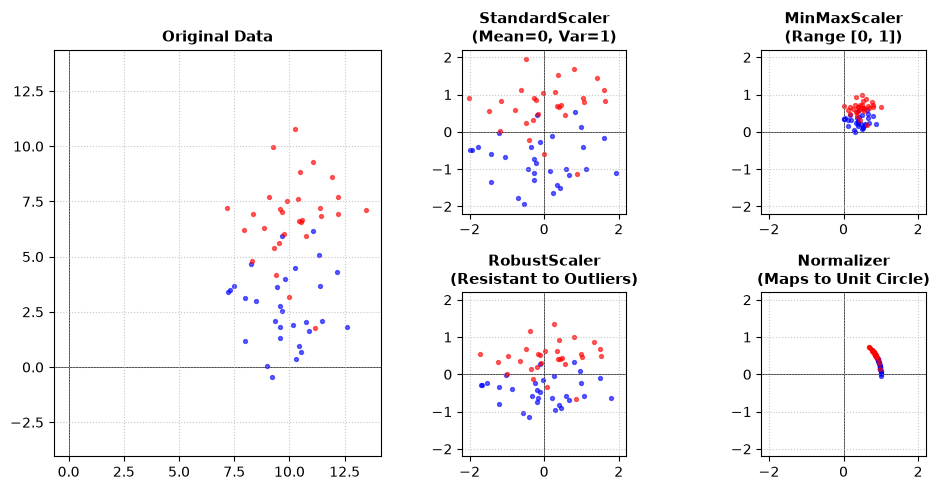

In [16]:


import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, Normalizer

# Generate synthetic dataset
np.random.seed(42)
n_samples = 30
cov = [[2, 0], [0, 4]] 

X0 = np.random.multivariate_normal([10, 3], cov, n_samples)
X1 = np.random.multivariate_normal([10, 7], cov, n_samples)
X = np.vstack((X0, X1))
y = np.hstack((np.zeros(n_samples), np.ones(n_samples)))

# Set up a 2x3 grid where the original data spans the entire left column
fig = plt.figure(figsize=(10, 5))
gs = fig.add_gridspec(2, 3, width_ratios=[1.2, 1, 1])

ax_orig = fig.add_subplot(gs[:, 0])
ax_std = fig.add_subplot(gs[0, 1])
ax_min = fig.add_subplot(gs[0, 2])
ax_rob = fig.add_subplot(gs[1, 1])
ax_norm = fig.add_subplot(gs[1, 2])

def plot_scaled(ax, X_scaled, title, show_axes=True, limits=None):
    _temp = ax.scatter(X_scaled[y==0, 0], X_scaled[y==0, 1], s=8, alpha=0.6, c='blue', label='Mean (10, 3)')
    _temp = ax.scatter(X_scaled[y==1, 0], X_scaled[y==1, 1], s=8, alpha=0.6, c='red', label='Mean (10, 7)')
    _temp = ax.set_title(title, fontsize=11, fontweight='bold')
    
    if show_axes:
        _temp = ax.axhline(0, color='black', lw=0.5, zorder=0)
        _temp = ax.axvline(0, color='black', lw=0.5, zorder=0)
        
    _temp = ax.grid(True, linestyle=':', alpha=0.7)
    
    if limits:
        _temp = ax.set_xlim(limits)
        _temp = ax.set_ylim(limits)
        _temp = ax.set_aspect('equal', adjustable='box')
    else:
        _temp = ax.set_aspect('equal', 'datalim')

# Plot Original and Scaled Versions
plot_scaled(ax_orig, X, "Original Data")

shared_limits = (-2.2, 2.2)
plot_scaled(ax_std, StandardScaler().fit_transform(X), "StandardScaler\n(Mean=0, Var=1)", limits=shared_limits)
plot_scaled(ax_min, MinMaxScaler().fit_transform(X), "MinMaxScaler\n(Range [0, 1])", limits=shared_limits)
plot_scaled(ax_rob, RobustScaler().fit_transform(X), "RobustScaler\n(Resistant to Outliers)", limits=shared_limits)
plot_scaled(ax_norm, Normalizer().fit_transform(X), "Normalizer\n(Maps to Unit Circle)", limits=shared_limits)

plt.tight_layout()
plt.show()



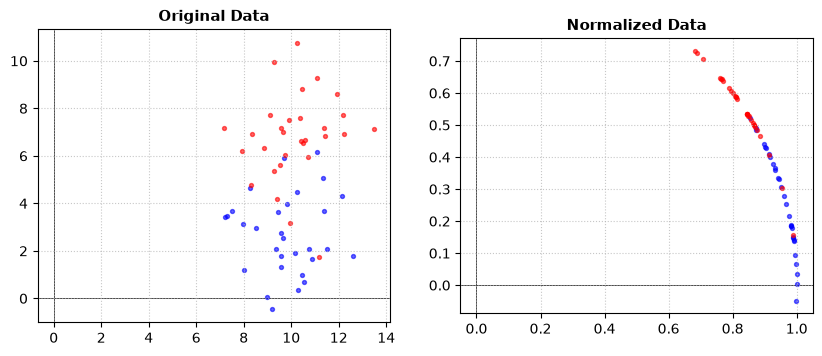

In [32]:


import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, Normalizer

# Generate synthetic dataset
np.random.seed(42)
n_samples = 30
cov = [[2, 0], [0, 4]] 

X0 = np.random.multivariate_normal([10, 3], cov, n_samples)
X1 = np.random.multivariate_normal([10, 7], cov, n_samples)
X = np.vstack((X0, X1))
y = np.hstack((np.zeros(n_samples), np.ones(n_samples)))

X_normalized = Normalizer().fit_transform(X)

# Plot Original and Normalized Versions
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].scatter(X[y==0, 0], X[y==0, 1], s=8, alpha=0.6, c='blue', label='Mean (10, 3)')
axes[0].scatter(X[y==1, 0], X[y==1, 1], s=8, alpha=0.6, c='red', label='Mean (10, 7)')
axes[0].set_title("Original Data", fontsize=11, fontweight='bold')
axes[0].axhline(0, color='black', lw=0.5, zorder=0)
axes[0].axvline(0, color='black', lw=0.5, zorder=0)
axes[0].grid(True, linestyle=':', alpha=0.7)
axes[0].set_aspect('equal', adjustable='box')

axes[1].scatter(X_normalized[y==0, 0], X_normalized[y==0, 1], s=8, alpha=0.6, c='blue', label='Mean (10, 3)')
axes[1].scatter(X_normalized[y==1, 0], X_normalized[y==1, 1], s=8, alpha=0.6, c='red', label='Mean (10, 7)')
axes[1].set_title("Normalized Data", fontsize=11, fontweight='bold')
axes[1].axhline(0, color='black', lw=0.5, zorder=0)
axes[1].axvline(0, color='black', lw=0.5, zorder=0)
axes[1].grid(True, linestyle=':', alpha=0.7)
axes[1].set_aspect('equal', adjustable='box')

plt.show()



In [ ]:


# Simulating leakage
np.random.seed(42)
X_full = np.random.normal(100, 25, 100).reshape(-1, 1)

# Bad Way
scaler_bad = StandardScaler().fit(X_full)
X_scaled_bad = scaler_bad.transform(X_full)
X_tr_bad, X_te_bad = train_test_split(X_scaled_bad, test_size=0.2, random_state=42)

# Good Way
X_tr_raw, X_te_raw = train_test_split(X_full, test_size=0.2, random_state=42)
scaler_good = StandardScaler().fit(X_tr_raw)
X_tr_good = scaler_good.transform(X_tr_raw)
X_te_good = scaler_good.transform(X_te_raw)

df_leak = pd.DataFrame({
    "Method": ["Scaled Before Split (Leakage)", "Scaled After Split (Correct)"],
    "Train Mean": [f"{X_tr_bad.mean():.4f}", f"{X_tr_good.mean():.4f}"],
    "Test Mean": [f"{X_te_bad.mean():.4f}", f"{X_te_good.mean():.4f}"]
})
print(df_leak.to_markdown(index=False))



| Method                        |   Train Mean |   Test Mean |
|:------------------------------|-------------:|------------:|
| Scaled Before Split (Leakage) |       -0.016 |      0.0638 |
| Scaled After Split (Correct)  |       -0     |      0.0775 |


In [18]:


pipe = Pipeline([('scaler', StandardScaler()), ('classifier', Ridge())])
pipe_nonames = make_pipeline(StandardScaler(), Ridge())
